# Your Title Here

**Name(s)**: (your name(s) here)

**Website Link**: (your website link)

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime
import seaborn as sns
import requests
import sklearn
import folium

import plotly.express as px
pd.options.plotting.backend = 'plotly'

# from dsc80_utils import * # Feel free to uncomment and use this.

## Step 1: Introduction

In [2]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [3]:
raw = pd.read_excel(Path('data') / 'outage.xlsx')
raw.head()

,Major power outage events in the continental U.S.,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 47,Unnamed: 48,Unnamed: 49,Unnamed: 50,Unnamed: 51,Unnamed: 52,Unnamed: 53,Unnamed: 54,Unnamed: 55,Unnamed: 56
0,Time period: January 2000 - July 2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Regions affected: Outages reported in this dat...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,variables,OBS,YEAR,MONTH,U.S._STATE,POSTAL.CODE,NERC.REGION,CLIMATE.REGION,ANOMALY.LEVEL,CLIMATE.CATEGORY,...,POPPCT_URBAN,POPPCT_UC,POPDEN_URBAN,POPDEN_UC,POPDEN_RURAL,AREAPCT_URBAN,AREAPCT_UC,PCT_LAND,PCT_WATER_TOT,PCT_WATER_INLAND


## Step 2: Data Cleaning and Exploratory Data Analysis

In [4]:
df = raw[6:].reset_index(drop=True).rename(columns=raw.iloc[4]).drop(['variables', 'OBS'], axis=1)
df.head()

,YEAR,MONTH,U.S._STATE,POSTAL.CODE,NERC.REGION,CLIMATE.REGION,ANOMALY.LEVEL,CLIMATE.CATEGORY,OUTAGE.START.DATE,OUTAGE.START.TIME,...,POPPCT_URBAN,POPPCT_UC,POPDEN_URBAN,POPDEN_UC,POPDEN_RURAL,AREAPCT_URBAN,AREAPCT_UC,PCT_LAND,PCT_WATER_TOT,PCT_WATER_INLAND
0,2011,7,Minnesota,MN,MRO,East North Central,-0.3,normal,2011-07-01 00:00:00,17:00:00,...,73.27,15.28,2279,1700.5,18.2,2.14,0.6,91.592666,8.407334,5.478743
1,2014,5,Minnesota,MN,MRO,East North Central,-0.1,normal,2014-05-11 00:00:00,18:38:00,...,73.27,15.28,2279,1700.5,18.2,2.14,0.6,91.592666,8.407334,5.478743
2,2010,10,Minnesota,MN,MRO,East North Central,-1.5,cold,2010-10-26 00:00:00,20:00:00,...,73.27,15.28,2279,1700.5,18.2,2.14,0.6,91.592666,8.407334,5.478743
3,2012,6,Minnesota,MN,MRO,East North Central,-0.1,normal,2012-06-19 00:00:00,04:30:00,...,73.27,15.28,2279,1700.5,18.2,2.14,0.6,91.592666,8.407334,5.478743
4,2015,7,Minnesota,MN,MRO,East North Central,1.2,warm,2015-07-18 00:00:00,02:00:00,...,73.27,15.28,2279,1700.5,18.2,2.14,0.6,91.592666,8.407334,5.478743


In [5]:
cleaned = df.copy()

def clean_datetime(row, col): 
    if pd.notna(row[f'OUTAGE.{col}.DATE']) and pd.notna(row[f'OUTAGE.{col}.TIME']):
        return datetime.combine(row[f'OUTAGE.{col}.DATE'].date(), row[f'OUTAGE.{col}.TIME'])

for col in ['START', 'RESTORATION']:
    cleaned[f'OUTAGE.{col}'] = df.apply(lambda row: clean_datetime(row, col), axis=1)
    cleaned.drop([f'OUTAGE.{col}.DATE', f'OUTAGE.{col}.TIME'], axis=1, inplace=True)
cleaned.head()

,YEAR,MONTH,U.S._STATE,POSTAL.CODE,NERC.REGION,CLIMATE.REGION,ANOMALY.LEVEL,CLIMATE.CATEGORY,CAUSE.CATEGORY,CAUSE.CATEGORY.DETAIL,...,POPDEN_URBAN,POPDEN_UC,POPDEN_RURAL,AREAPCT_URBAN,AREAPCT_UC,PCT_LAND,PCT_WATER_TOT,PCT_WATER_INLAND,OUTAGE.START,OUTAGE.RESTORATION
0,2011,7,Minnesota,MN,MRO,East North Central,-0.3,normal,severe weather,NaN,...,2279,1700.5,18.2,2.14,0.6,91.592666,8.407334,5.478743,2011-07-01 17:00:00,2011-07-03 20:00:00
1,2014,5,Minnesota,MN,MRO,East North Central,-0.1,normal,intentional attack,vandalism,...,2279,1700.5,18.2,2.14,0.6,91.592666,8.407334,5.478743,2014-05-11 18:38:00,2014-05-11 18:39:00
2,2010,10,Minnesota,MN,MRO,East North Central,-1.5,cold,severe weather,heavy wind,...,2279,1700.5,18.2,2.14,0.6,91.592666,8.407334,5.478743,2010-10-26 20:00:00,2010-10-28 22:00:00
3,2012,6,Minnesota,MN,MRO,East North Central,-0.1,normal,severe weather,thunderstorm,...,2279,1700.5,18.2,2.14,0.6,91.592666,8.407334,5.478743,2012-06-19 04:30:00,2012-06-20 23:00:00
4,2015,7,Minnesota,MN,MRO,East North Central,1.2,warm,severe weather,NaN,...,2279,1700.5,18.2,2.14,0.6,91.592666,8.407334,5.478743,2015-07-18 02:00:00,2015-07-19 07:00:00


In [6]:
state_geo = requests.get(
    "https://raw.githubusercontent.com/python-visualization/folium-example-data/main/us_states.json"
).json()

state_data = cleaned.groupby("POSTAL.CODE").size()

m = folium.Map(location=[48, -102], zoom_start=4)
folium.Choropleth(
    geo_data=state_geo,
    name="choropleth",
    data=state_data,
    columns=[state_data.index, state_data],
    key_on="feature.id",
    fill_color="YlOrRd",
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name="Power Outages",
).add_to(m)

In [7]:
cleaned.groupby("YEAR").size().plot(kind="bar", title="Number of Power Outages per Year")

In [76]:
cleaned.groupby("MONTH").size().plot(kind="bar", title="Number of Power Outages per Month")

In [77]:
cleaned.assign(TIME=cleaned["OUTAGE.START"].dt.strftime("%Y-%m")).groupby("TIME").size().plot()

In [100]:
def plot_monthly_average(df, cols):
    return px.line(df.dropna(subset=cols)
                   .assign(TIME=df["OUTAGE.START"].dt.strftime("%Y-%m"))
                   .groupby("TIME")[cols].mean())

log = lambda x: np.log(x) if x else np.nan
logs = cleaned.assign(
    LOG_DEMAND_LOSS_MW=cleaned["DEMAND.LOSS.MW"].apply(log),
    LOG_OUTAGE_DURATION=cleaned["OUTAGE.DURATION"].apply(log),
    LOG_CUSTOMERS_AFFECTED=cleaned["CUSTOMERS.AFFECTED"].apply(log),
)
plot_monthly_average(logs.query("`POSTAL.CODE` == 'CA'"), ["LOG_DEMAND_LOSS_MW", "LOG_OUTAGE_DURATION", "LOG_CUSTOMERS_AFFECTED"])

In [109]:
logs.plot(kind='scatter', x='UTIL.CONTRI', y='LOG_OUTAGE_DURATION')

<Axes: >

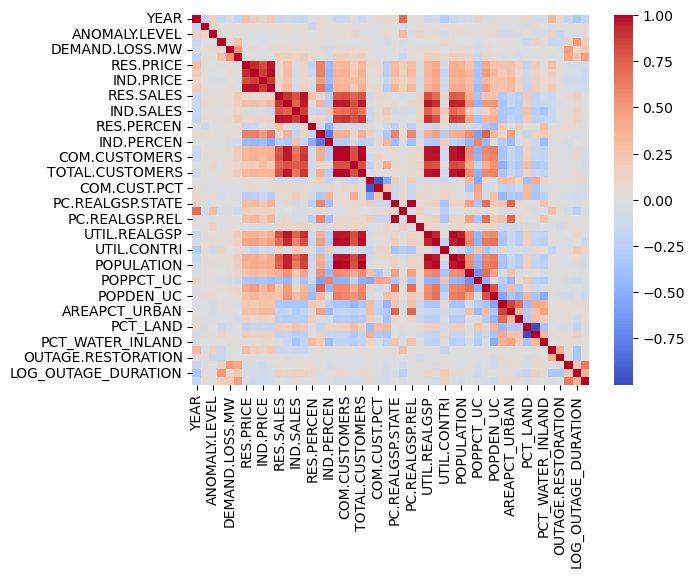

In [102]:
cat_cols = ["U.S._STATE", "POSTAL.CODE", "NERC.REGION", "CLIMATE.REGION", "CLIMATE.CATEGORY", "CAUSE.CATEGORY", "CAUSE.CATEGORY.DETAIL", "HURRICANE.NAMES"]
corr_matrix = logs.drop(cat_cols, axis=1).corr()
sns.heatmap(corr_matrix, cmap='coolwarm')

In [106]:
corr_matrix.loc["LOG_OUTAGE_DURATION"].apply(abs).sort_values(ascending=False).iloc[1:]

OUTAGE.DURATION           0.505447
LOG_CUSTOMERS_AFFECTED    0.353215
YEAR                      0.324978
OUTAGE.START              0.324300
OUTAGE.RESTORATION        0.322864
CUSTOMERS.AFFECTED        0.247294
LOG_DEMAND_LOSS_MW        0.231851
PC.REALGSP.USA            0.215041
UTIL.CONTRI               0.200287
PCT_LAND                  0.159314
PCT_WATER_TOT             0.159293
RES.SALES                 0.141430
IND.SALES                 0.140721
TOTAL.SALES               0.132957
POPPCT_UC                 0.114967
AREAPCT_UC                0.112469
UTIL.REALGSP              0.102360
IND.CUST.PCT              0.099949
COM.SALES                 0.098209
IND.PRICE                 0.092686
PI.UTIL.OFUSA             0.085749
RES.PRICE                 0.083216
COM.CUSTOMERS             0.081595
RES.CUSTOMERS             0.081354
TOTAL.CUSTOMERS           0.080750
COM.PRICE                 0.076510
DEMAND.LOSS.MW            0.075979
TOTAL.PRICE               0.074407
RES.PERCEN          

In [12]:
pd.pivot_table(cleaned, index="CLIMATE.CATEGORY", columns="CLIMATE.REGION", values="CUSTOMERS.AFFECTED", aggfunc="mean").astype(int)

CLIMATE.REGION,Central,East North Central,Northeast,Northwest,South,Southeast,Southwest,West,West North Central
CLIMATE.CATEGORY,,,,,,,,,
cold,97364,120777,120320,63350,186070,142545,63196,171929,53500
normal,154125,154612,125290,42961,218077,164578,24918,186293,60106
warm,91868,101710,115443,118436,107234,268593,29596,231771,25250


## Step 3: Assessment of Missingness

In [13]:
# TODO

## Step 4: Hypothesis Testing

In [14]:
tvd = lambda x, y: np.abs(x - y).sum() / 2
uniform = np.ones(12) / 12
month_props = cleaned.value_counts("MONTH", normalize=True).values
observed = tvd(month_props, uniform)

stats = np.array([])
for _ in range(1000):
    rand = np.random.choice(12, size=cleaned.shape[0], p=uniform)
    stat = pd.Series(rand).value_counts(normalize=True)
    stats = np.append(stats, tvd(stat, uniform))
    
(stats >= observed).mean()

np.float64(0.0)

## Step 5: Framing a Prediction Problem

In [15]:
# TODO

## Step 6: Baseline Model

In [16]:
cleaned.columns

Index(['YEAR', 'MONTH', 'U.S._STATE', 'POSTAL.CODE', 'NERC.REGION',
       'CLIMATE.REGION', 'ANOMALY.LEVEL', 'CLIMATE.CATEGORY', 'CAUSE.CATEGORY',
       'CAUSE.CATEGORY.DETAIL', 'HURRICANE.NAMES', 'OUTAGE.DURATION',
       'DEMAND.LOSS.MW', 'CUSTOMERS.AFFECTED', 'RES.PRICE', 'COM.PRICE',
       'IND.PRICE', 'TOTAL.PRICE', 'RES.SALES', 'COM.SALES', 'IND.SALES',
       'TOTAL.SALES', 'RES.PERCEN', 'COM.PERCEN', 'IND.PERCEN',
       'RES.CUSTOMERS', 'COM.CUSTOMERS', 'IND.CUSTOMERS', 'TOTAL.CUSTOMERS',
       'RES.CUST.PCT', 'COM.CUST.PCT', 'IND.CUST.PCT', 'PC.REALGSP.STATE',
       'PC.REALGSP.USA', 'PC.REALGSP.REL', 'PC.REALGSP.CHANGE', 'UTIL.REALGSP',
       'TOTAL.REALGSP', 'UTIL.CONTRI', 'PI.UTIL.OFUSA', 'POPULATION',
       'POPPCT_URBAN', 'POPPCT_UC', 'POPDEN_URBAN', 'POPDEN_UC',
       'POPDEN_RURAL', 'AREAPCT_URBAN', 'AREAPCT_UC', 'PCT_LAND',
       'PCT_WATER_TOT', 'PCT_WATER_INLAND', 'OUTAGE.START',
       'OUTAGE.RESTORATION'],
      dtype='object')

## Step 7: Final Model

In [17]:
# TODO

## Step 8: Fairness Analysis

In [18]:
# TODO